# Trip Type and Rate Code Analysis
## Investigating the Effect on Trip Duration

This notebook analyzes how `trip_type` and `rate_code` affect trip duration predictions.

**Hypothesis**: 
- Long-duration trips with low predictions may be due to special rate codes (negotiated fare, flat rate) or trip types (dispatch vs street-hail)
- These trips may not follow the distance-duration relationship, making them unpredictable with current features
- If we removed these features during cleaning, we lost critical information for certain trip categories

**Analysis Steps**:
1. Load original data with `trip_type` and `rate_code`
2. Analyze distribution of these features
3. Check relationship between `trip_type`, `rate_code`, and `trip_duration`
4. Identify problematic trip categories
5. Recommend filtering or feature engineering strategies

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

## 1. Load Original Data with trip_type and rate_code

In [15]:
# Load original data
df_original = pd.read_csv('bq-results-20251021-151536-1761059869369.csv', dtype_backend='pyarrow')
df_original.drop(columns=['data_file_year','data_file_month'], inplace=True)

print("Original dataset shape:", df_original.shape)
print("\nColumns available:")
print(df_original.columns.tolist())

Original dataset shape: (1068744, 22)

Columns available:
['vendor_id', 'pickup_datetime', 'dropoff_datetime', 'store_and_fwd_flag', 'rate_code', 'passenger_count', 'trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'ehail_fee', 'airport_fee', 'total_amount', 'payment_type', 'distance_between_service', 'time_between_service', 'trip_type', 'imp_surcharge', 'pickup_location_id', 'dropoff_location_id']


In [16]:
# Load taxi zone lookup for borough information
taxi_zone_lookup_df = pd.read_csv('taxi_zone_lookup.csv', dtype_backend='pyarrow')

# Merge for dropoff location
df_original = df_original.merge(taxi_zone_lookup_df[['LocationID', 'Borough']], 
                                 left_on='dropoff_location_id', right_on='LocationID', how='left')
df_original.rename(columns={'Borough': 'dropoff_borough'}, inplace=True)
df_original.drop(columns=['LocationID'], inplace=True)

# Merge for pickup location
df_original = df_original.merge(taxi_zone_lookup_df[['LocationID', 'Borough']], 
                                left_on='pickup_location_id', right_on='LocationID', how='left')
df_original.rename(columns={'Borough': 'pickup_borough'}, inplace=True)
df_original.drop(columns=['LocationID'], inplace=True)

# Drop location IDs
df_original.drop(columns=['dropoff_location_id', 'pickup_location_id'], inplace=True)

# Process datetime and calculate trip duration
df_original = df_original.dropna(axis=1, how='all')
df_original['pickup_datetime'] = pd.to_datetime(df_original['pickup_datetime'])
df_original['dropoff_datetime'] = pd.to_datetime(df_original['dropoff_datetime'])
df_original['trip_duration'] = (df_original['dropoff_datetime'] - df_original['pickup_datetime']).dt.total_seconds() / 60

print(f"\nDataset shape after preprocessing: {df_original.shape}")


Dataset shape after preprocessing: (1068744, 19)


In [17]:
# Apply basic validation rules (same as data_cleaning.ipynb)
df_original = df_original[df_original['trip_duration'] > 0]
df_original = df_original[df_original['trip_distance'] > 0]
df_original = df_original[df_original['total_amount'] > 0]
df_original = df_original[df_original['fare_amount'] > 0]
df_original = df_original[(df_original['payment_type'] >= 1) & (df_original['payment_type'] <= 6)]

print(f"Dataset shape after validation: {df_original.shape}")
print(f"\nDataset info:")
df_original.info()

Dataset shape after validation: (619101, 19)

Dataset info:
<class 'pandas.core.frame.DataFrame'>
Index: 619101 entries, 41 to 1068655
Data columns (total 19 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   vendor_id           619101 non-null  int64[pyarrow]     
 1   pickup_datetime     619101 non-null  datetime64[ns, UTC]
 2   dropoff_datetime    619101 non-null  datetime64[ns, UTC]
 3   store_and_fwd_flag  619101 non-null  string[pyarrow]    
 4   rate_code           619101 non-null  double[pyarrow]    
 5   passenger_count     619101 non-null  int64[pyarrow]     
 6   trip_distance       619101 non-null  double[pyarrow]    
 7   fare_amount         619101 non-null  double[pyarrow]    
 8   extra               619101 non-null  double[pyarrow]    
 9   mta_tax             619101 non-null  double[pyarrow]    
 10  tip_amount          619101 non-null  double[pyarrow]    
 11  tolls_amount        6

## 2. Analyze trip_type Distribution and Meaning

TRIP_TYPE ANALYSIS

Trip Type Distribution:
trip_type
1.0    602703
2.0     16398
Name: count, dtype: int64[pyarrow]

Percentage distribution:
trip_type
1.0    97.35
2.0     2.65
Name: count, dtype: double[pyarrow]

📖 Trip Type Codes (NYC TLC):
   1 = Street-hail (passenger flags down taxi)
   2 = Dispatch (pre-arranged, called in advance)


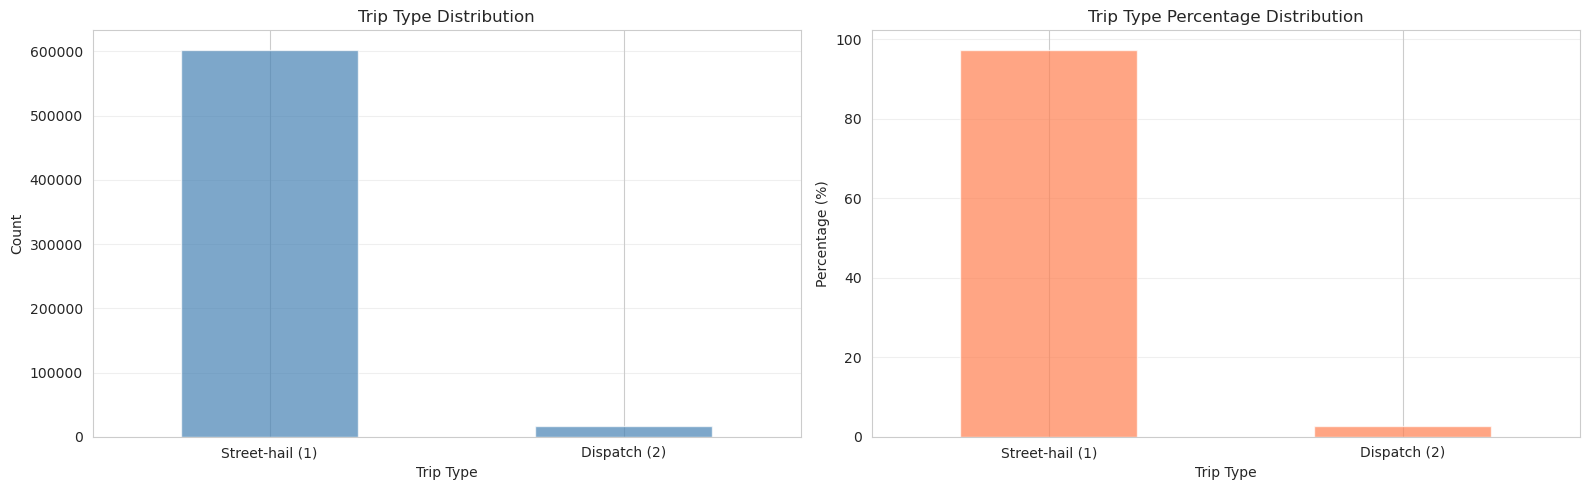

In [18]:
# Check if trip_type exists
if 'trip_type' in df_original.columns:
    print("="*80)
    print("TRIP_TYPE ANALYSIS")
    print("="*80)
    
    print("\nTrip Type Distribution:")
    trip_type_counts = df_original['trip_type'].value_counts().sort_index()
    print(trip_type_counts)
    print(f"\nPercentage distribution:")
    print((trip_type_counts / len(df_original) * 100).round(2))
    
    # According to NYC TLC data dictionary:
    # trip_type: 1 = Street-hail, 2 = Dispatch
    print("\n📖 Trip Type Codes (NYC TLC):")
    print("   1 = Street-hail (passenger flags down taxi)")
    print("   2 = Dispatch (pre-arranged, called in advance)")
    
    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Count plot
    trip_type_counts.plot(kind='bar', ax=axes[0], color='steelblue', alpha=0.7)
    axes[0].set_xlabel('Trip Type')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Trip Type Distribution')
    axes[0].set_xticklabels(['Street-hail (1)', 'Dispatch (2)'], rotation=0)
    axes[0].grid(True, alpha=0.3, axis='y')
    
    # Percentage plot
    (trip_type_counts / len(df_original) * 100).plot(kind='bar', ax=axes[1], color='coral', alpha=0.7)
    axes[1].set_xlabel('Trip Type')
    axes[1].set_ylabel('Percentage (%)')
    axes[1].set_title('Trip Type Percentage Distribution')
    axes[1].set_xticklabels(['Street-hail (1)', 'Dispatch (2)'], rotation=0)
    axes[1].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
else:
    print("⚠️  WARNING: trip_type column not found in dataset!")
    print("This column may have been dropped during earlier processing.")

## 3. Analyze rate_code Distribution and Meaning

RATE_CODE ANALYSIS

Rate Code Distribution:
rate_code
1.0    598439
2.0      1429
3.0       201
4.0       638
5.0     18391
6.0         3
Name: count, dtype: int64[pyarrow]

Percentage distribution:
rate_code
1.0    96.66
2.0     0.23
3.0     0.03
4.0      0.1
5.0     2.97
6.0      0.0
Name: count, dtype: double[pyarrow]

📖 Rate Code Meanings (NYC TLC):
   1 = Standard rate (metered fare)
   2 = JFK (flat fare to/from JFK Airport)
   3 = Newark (flat fare to/from Newark Airport)
   4 = Nassau or Westchester (negotiated fare)
   5 = Negotiated fare (other)
   6 = Group ride
   99 = Unknown


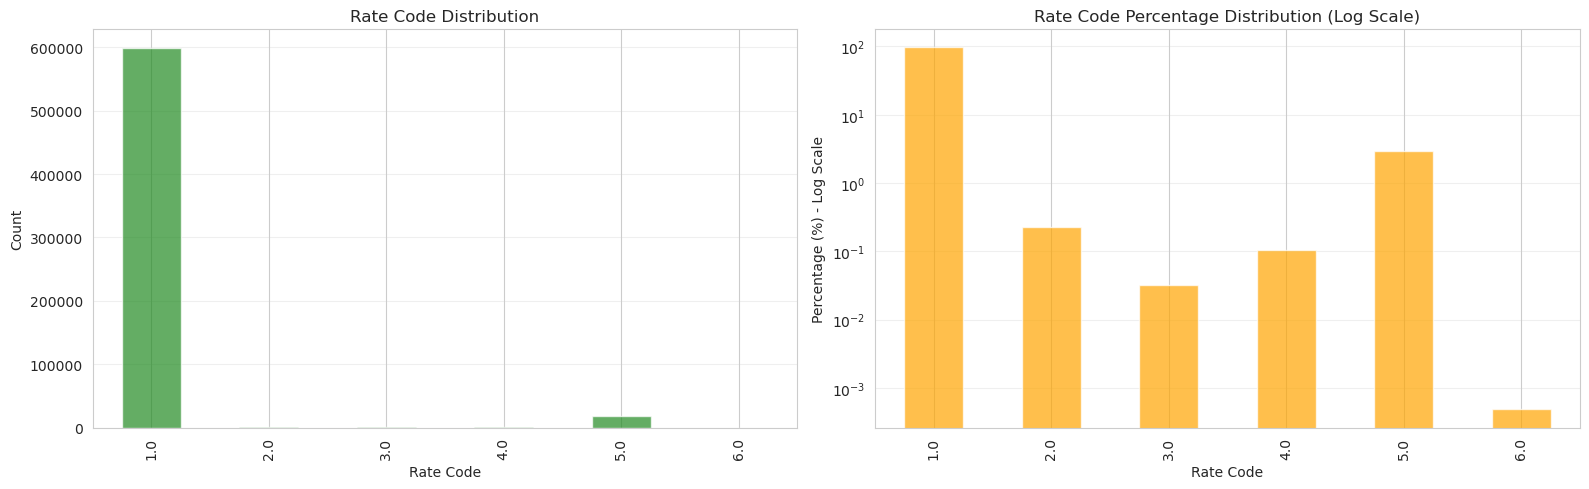

In [19]:
# Check if rate_code exists
if 'rate_code' in df_original.columns:
    print("="*80)
    print("RATE_CODE ANALYSIS")
    print("="*80)
    
    print("\nRate Code Distribution:")
    rate_code_counts = df_original['rate_code'].value_counts().sort_index()
    print(rate_code_counts)
    print(f"\nPercentage distribution:")
    print((rate_code_counts / len(df_original) * 100).round(2))
    
    # According to NYC TLC data dictionary:
    print("\n📖 Rate Code Meanings (NYC TLC):")
    print("   1 = Standard rate (metered fare)")
    print("   2 = JFK (flat fare to/from JFK Airport)")
    print("   3 = Newark (flat fare to/from Newark Airport)")
    print("   4 = Nassau or Westchester (negotiated fare)")
    print("   5 = Negotiated fare (other)")
    print("   6 = Group ride")
    print("   99 = Unknown")
    
    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Count plot
    rate_code_counts.plot(kind='bar', ax=axes[0], color='forestgreen', alpha=0.7)
    axes[0].set_xlabel('Rate Code')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Rate Code Distribution')
    axes[0].grid(True, alpha=0.3, axis='y')
    
    # Percentage plot (log scale for better visibility)
    (rate_code_counts / len(df_original) * 100).plot(kind='bar', ax=axes[1], color='orange', alpha=0.7)
    axes[1].set_xlabel('Rate Code')
    axes[1].set_ylabel('Percentage (%) - Log Scale')
    axes[1].set_title('Rate Code Percentage Distribution (Log Scale)')
    axes[1].set_yscale('log')
    axes[1].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
else:
    print("⚠️  WARNING: rate_code column not found in dataset!")
    print("This column may have been dropped during earlier processing.")

## 4. Relationship: trip_type vs trip_duration

TRIP_TYPE vs TRIP_DURATION ANALYSIS

Trip Duration Statistics by Trip Type:


,count,mean,std,min,25%,50%,75%,max
trip_type,,,,,,,,
1.0,602703.0,23.867898,96.682662,0.016667,7.533333,12.216667,20.033333,1439.85
2.0,16398.0,27.196972,119.368726,0.016667,5.116667,12.833333,21.950000,1438.85



📊 Dispatch (2) trips are 1.14x longer than Street-hail (1) trips
   Mean difference: 3.33 minutes


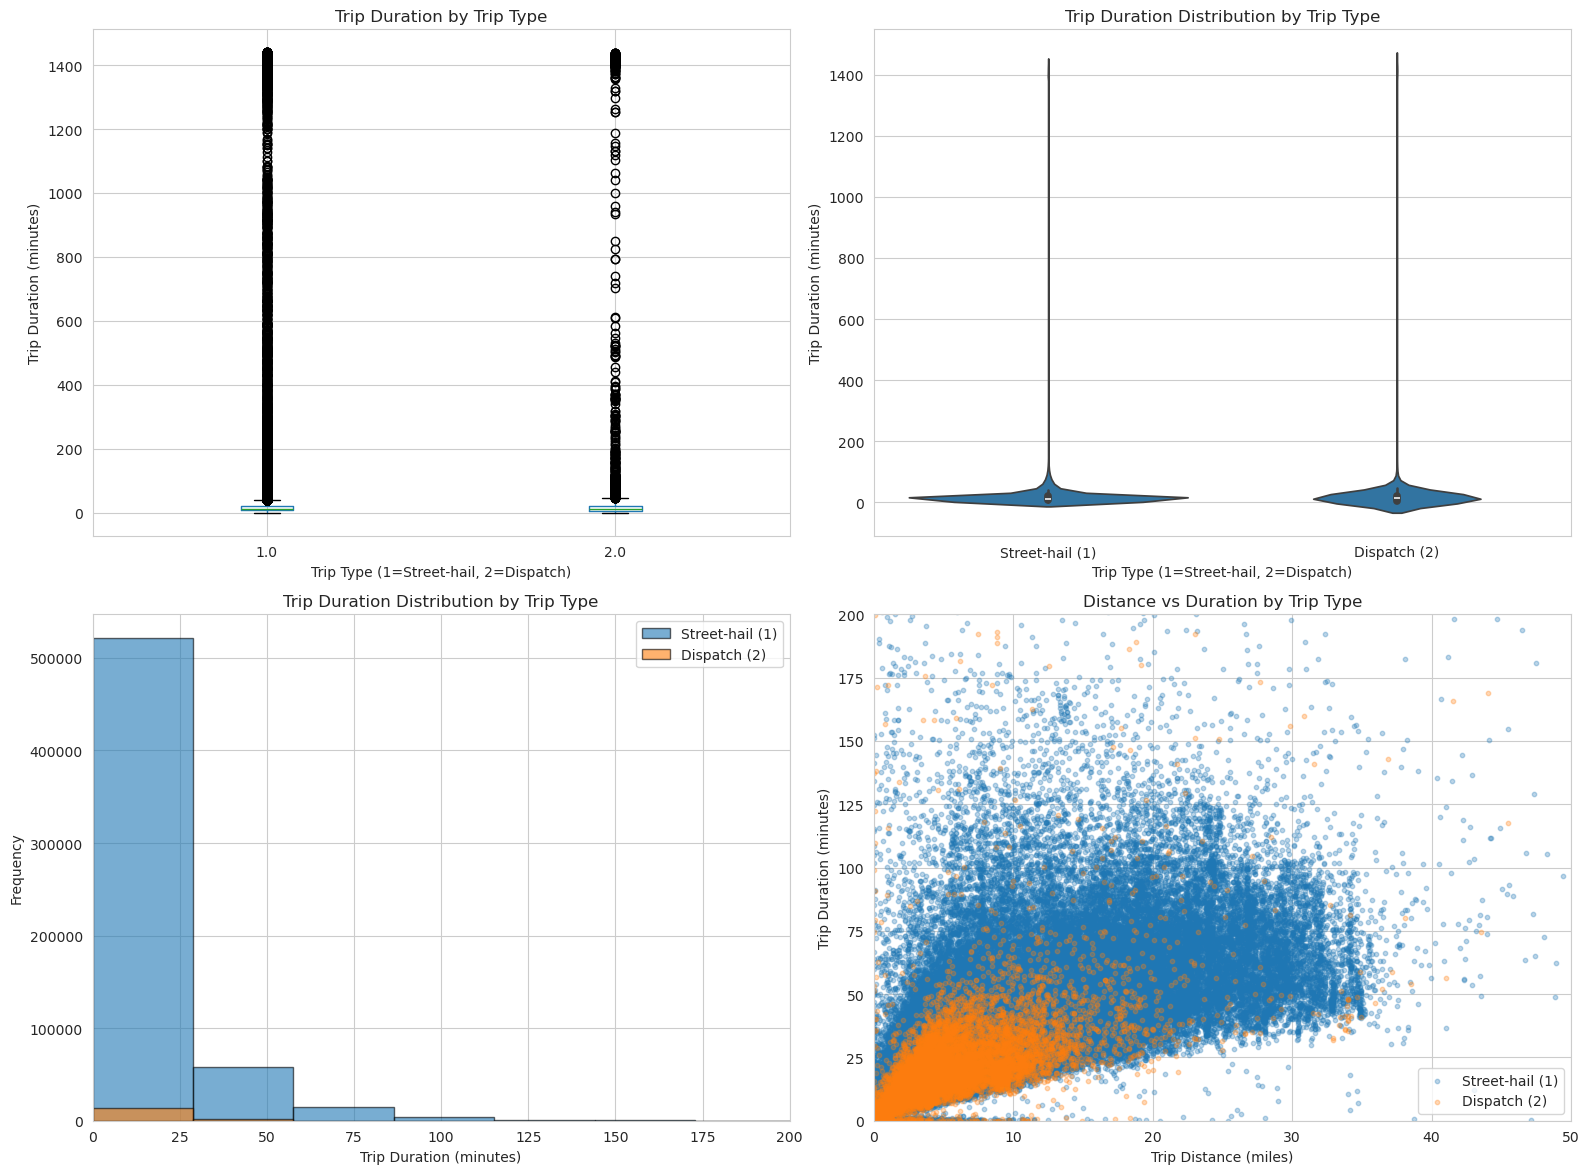


📈 Statistical Test (Mann-Whitney U):
   Test statistic: 5189574470.00
   P-value: 4.59e-28
   ✅ HIGHLY SIGNIFICANT difference between trip types!


In [20]:
if 'trip_type' in df_original.columns:
    print("="*80)
    print("TRIP_TYPE vs TRIP_DURATION ANALYSIS")
    print("="*80)
    
    # Statistics by trip type
    trip_duration_by_type = df_original.groupby('trip_type')['trip_duration'].describe()
    print("\nTrip Duration Statistics by Trip Type:")
    display(trip_duration_by_type)
    
    # Calculate ratio and difference
    if len(trip_duration_by_type) == 2:
        mean_ratio = trip_duration_by_type.loc[2, 'mean'] / trip_duration_by_type.loc[1, 'mean']
        mean_diff = trip_duration_by_type.loc[2, 'mean'] - trip_duration_by_type.loc[1, 'mean']
        print(f"\n📊 Dispatch (2) trips are {mean_ratio:.2f}x longer than Street-hail (1) trips")
        print(f"   Mean difference: {mean_diff:.2f} minutes")
    
    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Box plot
    df_original.boxplot(column='trip_duration', by='trip_type', ax=axes[0, 0])
    axes[0, 0].set_xlabel('Trip Type (1=Street-hail, 2=Dispatch)')
    axes[0, 0].set_ylabel('Trip Duration (minutes)')
    axes[0, 0].set_title('Trip Duration by Trip Type')
    axes[0, 0].get_figure().suptitle('')
    
    # Violin plot
    sns.violinplot(data=df_original, x='trip_type', y='trip_duration', ax=axes[0, 1])
    axes[0, 1].set_xlabel('Trip Type (1=Street-hail, 2=Dispatch)')
    axes[0, 1].set_ylabel('Trip Duration (minutes)')
    axes[0, 1].set_title('Trip Duration Distribution by Trip Type')
    axes[0, 1].set_xticklabels(['Street-hail (1)', 'Dispatch (2)'])
    
    # Histogram comparison
    for trip_type in sorted(df_original['trip_type'].unique()):
        data = df_original[df_original['trip_type'] == trip_type]['trip_duration']
        label = 'Street-hail (1)' if trip_type == 1 else 'Dispatch (2)'
        axes[1, 0].hist(data, bins=50, alpha=0.6, label=label, edgecolor='black')
    axes[1, 0].set_xlabel('Trip Duration (minutes)')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Trip Duration Distribution by Trip Type')
    axes[1, 0].legend()
    axes[1, 0].set_xlim(0, 200)
    
    # Scatter plot: trip_distance vs trip_duration colored by trip_type
    for trip_type in sorted(df_original['trip_type'].unique()):
        data = df_original[df_original['trip_type'] == trip_type]
        label = 'Street-hail (1)' if trip_type == 1 else 'Dispatch (2)'
        axes[1, 1].scatter(data['trip_distance'], data['trip_duration'], 
                          alpha=0.3, s=10, label=label)
    axes[1, 1].set_xlabel('Trip Distance (miles)')
    axes[1, 1].set_ylabel('Trip Duration (minutes)')
    axes[1, 1].set_title('Distance vs Duration by Trip Type')
    axes[1, 1].legend()
    axes[1, 1].set_xlim(0, 50)
    axes[1, 1].set_ylim(0, 200)
    
    plt.tight_layout()
    plt.show()
    
    # Statistical test
    if len(df_original['trip_type'].unique()) == 2:
        type1_duration = df_original[df_original['trip_type'] == 1]['trip_duration']
        type2_duration = df_original[df_original['trip_type'] == 2]['trip_duration']
        
        # Mann-Whitney U test (non-parametric)
        statistic, pvalue = stats.mannwhitneyu(type1_duration, type2_duration, alternative='two-sided')
        
        print("\n📈 Statistical Test (Mann-Whitney U):")
        print(f"   Test statistic: {statistic:.2f}")
        print(f"   P-value: {pvalue:.2e}")
        if pvalue < 0.001:
            print("   ✅ HIGHLY SIGNIFICANT difference between trip types!")
        elif pvalue < 0.05:
            print("   ✅ Significant difference between trip types")
        else:
            print("   ⚠️  No significant difference between trip types")

## 5. Relationship: rate_code vs trip_duration

RATE_CODE vs TRIP_DURATION ANALYSIS

Trip Duration Statistics by Rate Code:


,count,mean,std,min,25%,50%,75%,max
rate_code,,,,,,,,
1.0,598439.0,23.702912,96.363836,0.016667,7.516667,12.166667,19.883333,1439.850000
2.0,1429.0,55.164684,152.196364,0.033333,27.033333,39.050000,51.950000,1439.666667
3.0,201.0,39.318740,102.579304,0.016667,1.366667,34.166667,49.000000,1425.183333
4.0,638.0,62.402665,161.600879,4.383333,26.020833,33.566667,49.258333,1429.150000
5.0,18391.0,28.270908,117.968285,0.016667,5.733333,13.583333,23.100000,1438.850000
6.0,3.0,2.155556,1.015482,0.983333,1.850000,2.716667,2.741667,2.766667



📊 Trip Duration Comparison (vs Standard Rate Code 1):
   Rate Code 2.0: 55.16 min (Δ +31.46 min, 2.33x)
   Rate Code 3.0: 39.32 min (Δ +15.62 min, 1.66x)
   Rate Code 4.0: 62.40 min (Δ +38.70 min, 2.63x)
   Rate Code 5.0: 28.27 min (Δ +4.57 min, 1.19x)
   Rate Code 6.0: 2.16 min (Δ -21.55 min, 0.09x)


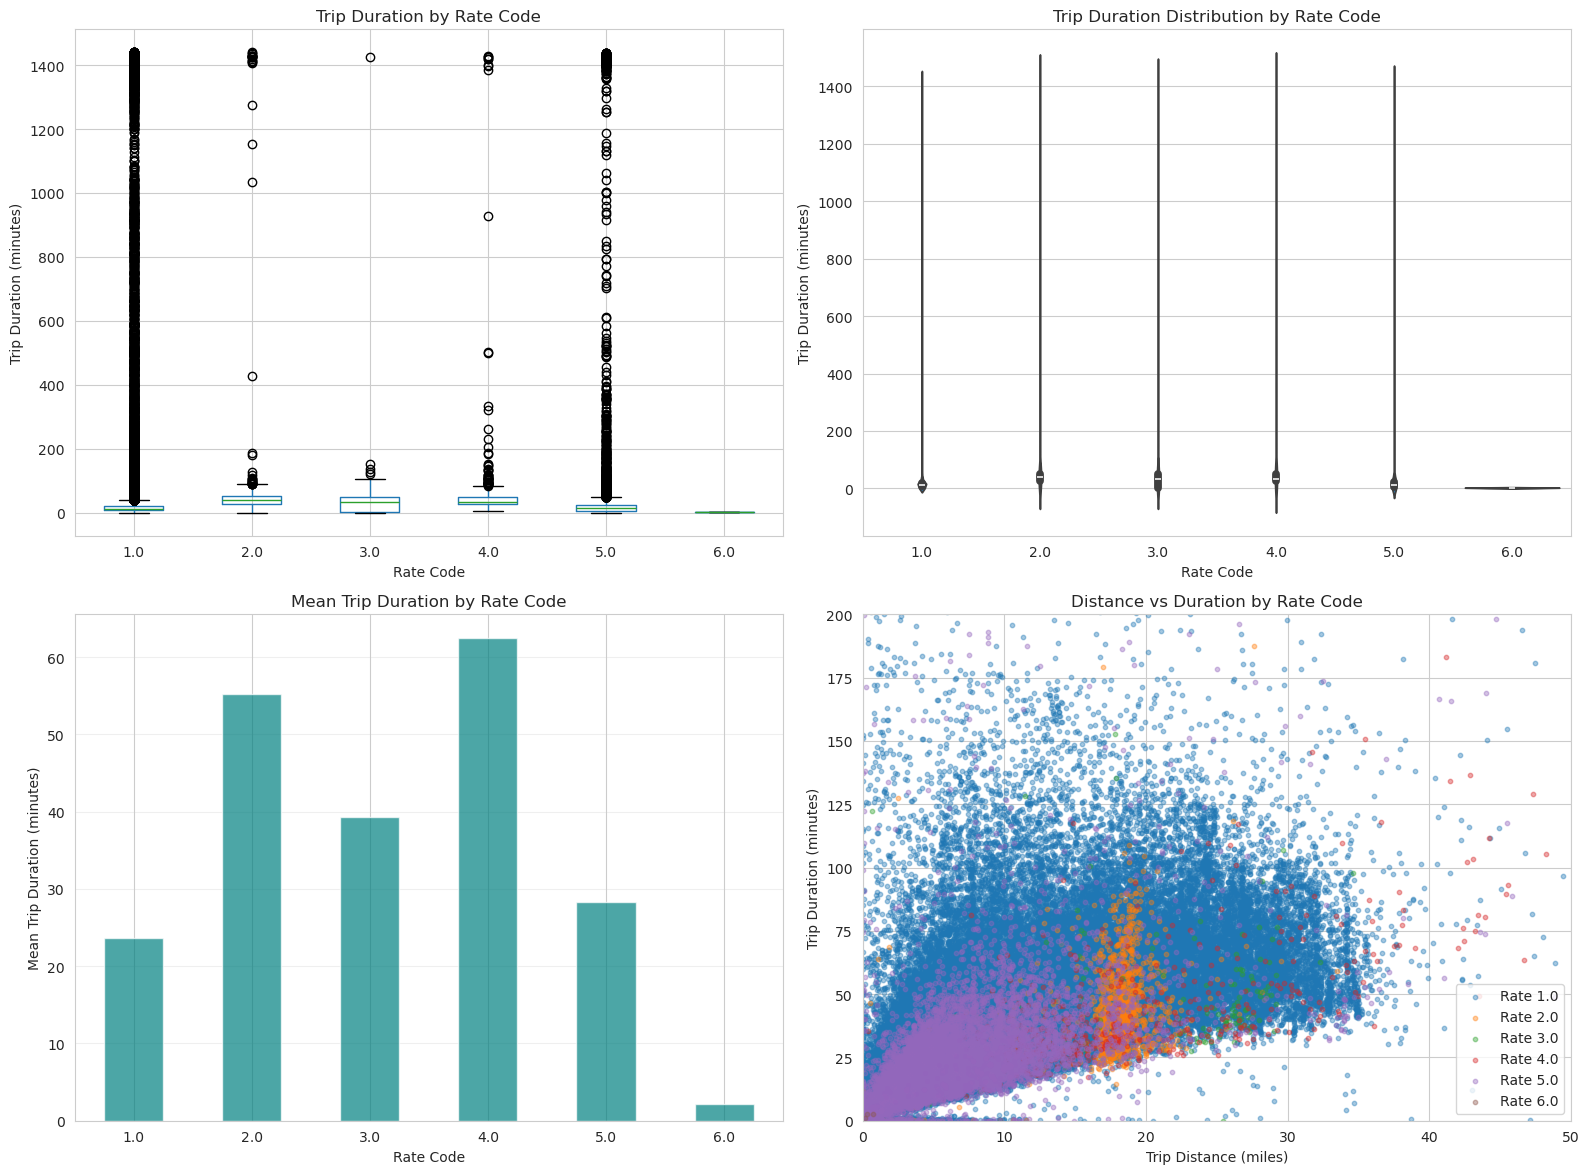


📈 Statistical Test (Kruskal-Wallis):
   Test statistic: 2275.35
   P-value: 0.00e+00
   ✅ HIGHLY SIGNIFICANT difference across rate codes!


In [21]:
if 'rate_code' in df_original.columns:
    print("="*80)
    print("RATE_CODE vs TRIP_DURATION ANALYSIS")
    print("="*80)
    
    # Statistics by rate code
    trip_duration_by_rate = df_original.groupby('rate_code')['trip_duration'].describe()
    print("\nTrip Duration Statistics by Rate Code:")
    display(trip_duration_by_rate)
    
    # Highlight differences
    if 1 in trip_duration_by_rate.index:
        standard_mean = trip_duration_by_rate.loc[1, 'mean']
        print(f"\n📊 Trip Duration Comparison (vs Standard Rate Code 1):")
        for rate_code in trip_duration_by_rate.index:
            if rate_code != 1:
                mean_val = trip_duration_by_rate.loc[rate_code, 'mean']
                ratio = mean_val / standard_mean
                diff = mean_val - standard_mean
                print(f"   Rate Code {rate_code}: {mean_val:.2f} min (Δ {diff:+.2f} min, {ratio:.2f}x)")
    
    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Box plot
    df_original.boxplot(column='trip_duration', by='rate_code', ax=axes[0, 0])
    axes[0, 0].set_xlabel('Rate Code')
    axes[0, 0].set_ylabel('Trip Duration (minutes)')
    axes[0, 0].set_title('Trip Duration by Rate Code')
    axes[0, 0].get_figure().suptitle('')
    axes[0, 0].tick_params(axis='x', rotation=0)
    
    # Violin plot
    sns.violinplot(data=df_original, x='rate_code', y='trip_duration', ax=axes[0, 1])
    axes[0, 1].set_xlabel('Rate Code')
    axes[0, 1].set_ylabel('Trip Duration (minutes)')
    axes[0, 1].set_title('Trip Duration Distribution by Rate Code')
    
    # Bar plot of mean duration
    mean_duration = df_original.groupby('rate_code')['trip_duration'].mean()
    mean_duration.plot(kind='bar', ax=axes[1, 0], color='teal', alpha=0.7)
    axes[1, 0].set_xlabel('Rate Code')
    axes[1, 0].set_ylabel('Mean Trip Duration (minutes)')
    axes[1, 0].set_title('Mean Trip Duration by Rate Code')
    axes[1, 0].tick_params(axis='x', rotation=0)
    axes[1, 0].grid(True, alpha=0.3, axis='y')
    
    # Scatter plot: trip_distance vs trip_duration colored by rate_code
    for rate_code in sorted(df_original['rate_code'].unique()):
        data = df_original[df_original['rate_code'] == rate_code]
        axes[1, 1].scatter(data['trip_distance'], data['trip_duration'], 
                          alpha=0.4, s=10, label=f'Rate {rate_code}')
    axes[1, 1].set_xlabel('Trip Distance (miles)')
    axes[1, 1].set_ylabel('Trip Duration (minutes)')
    axes[1, 1].set_title('Distance vs Duration by Rate Code')
    axes[1, 1].legend()
    axes[1, 1].set_xlim(0, 50)
    axes[1, 1].set_ylim(0, 200)
    
    plt.tight_layout()
    plt.show()
    
    # Kruskal-Wallis test (non-parametric ANOVA)
    groups = [df_original[df_original['rate_code'] == rc]['trip_duration'].values 
              for rc in df_original['rate_code'].unique()]
    statistic, pvalue = stats.kruskal(*groups)
    
    print("\n📈 Statistical Test (Kruskal-Wallis):")
    print(f"   Test statistic: {statistic:.2f}")
    print(f"   P-value: {pvalue:.2e}")
    if pvalue < 0.001:
        print("   ✅ HIGHLY SIGNIFICANT difference across rate codes!")
    elif pvalue < 0.05:
        print("   ✅ Significant difference across rate codes")
    else:
        print("   ⚠️  No significant difference across rate codes")

## 6. Identify Problematic Trip Categories

Let's identify trips that are "long duration but short distance" - these are likely the unpredictable ones.

In [22]:
# Verify actual trip duration range in the data
print("="*80)
print("ACTUAL DATA RANGE (Not limited by visualization)")
print("="*80)
print(f"\nTrip Duration Statistics:")
print(f"  Minimum: {df_original['trip_duration'].min():.2f} minutes")
print(f"  Maximum: {df_original['trip_duration'].max():.2f} minutes")
print(f"  Mean: {df_original['trip_duration'].mean():.2f} minutes")
print(f"  Median: {df_original['trip_duration'].median():.2f} minutes")
print(f"  95th percentile: {df_original['trip_duration'].quantile(0.95):.2f} minutes")
print(f"  99th percentile: {df_original['trip_duration'].quantile(0.99):.2f} minutes")

# Count trips over 200 minutes
trips_over_200 = (df_original['trip_duration'] > 200).sum()
trips_over_200_pct = (trips_over_200 / len(df_original)) * 100
print(f"\n⚠️  Trips over 200 minutes: {trips_over_200:,} ({trips_over_200_pct:.2f}%)")
print("   These trips exist but are CUT OFF in the 0-200 minute visualizations!")

# Count trips over 1000 minutes
trips_over_1000 = (df_original['trip_duration'] > 1000).sum()
trips_over_1000_pct = (trips_over_1000 / len(df_original)) * 100
print(f"   Trips over 1000 minutes: {trips_over_1000:,} ({trips_over_1000_pct:.2f}%)")

# Show some extreme examples
print(f"\n📊 Longest trips in dataset:")
longest_trips = df_original.nlargest(10, 'trip_duration')[['trip_duration', 'trip_distance', 'rate_code', 'total_amount', 'pickup_borough', 'dropoff_borough']]
display(longest_trips)


ACTUAL DATA RANGE (Not limited by visualization)

Trip Duration Statistics:
  Minimum: 0.02 minutes
  Maximum: 1439.85 minutes
  Mean: 23.96 minutes
  Median: 12.23 minutes
  95th percentile: 50.77 minutes
  99th percentile: 105.25 minutes

⚠️  Trips over 200 minutes: 3,818 (0.62%)
   These trips exist but are CUT OFF in the 0-200 minute visualizations!
   Trips over 1000 minutes: 2,873 (0.46%)

📊 Longest trips in dataset:


,trip_duration,trip_distance,rate_code,total_amount,pickup_borough,dropoff_borough
224398,1439.850000,0.2,1.0,3.8,Brooklyn,Brooklyn
508754,1439.850000,4.2,1.0,20.46,Brooklyn,Manhattan
63890,1439.766667,4.39,1.0,21.55,Manhattan,Manhattan
240935,1439.750000,13.97,1.0,69.12,Manhattan,Brooklyn
774807,1439.716667,17.64,1.0,60.05,Manhattan,Brooklyn
151224,1439.666667,18.1,2.0,69.35,Manhattan,Queens
36989,1439.650000,0.98,1.0,9.8,Manhattan,Manhattan
337244,1439.650000,6.39,1.0,20.8,Queens,Queens
66017,1439.616667,1.89,1.0,13.8,Manhattan,Bronx
22518,1439.366667,5.14,1.0,31.55,Brooklyn,Manhattan


**Note on Visualizations**: The previous charts limited the y-axis to 0-200 minutes for better visibility of the main distribution (where 95%+ of trips are). However, the actual dataset contains trips up to 1400+ minutes! Let's verify the full range.

IDENTIFYING PROBLEMATIC TRIPS

Trip Category Distribution:
trip_category
Normal                           609167
Very Slow (<3 mph)                 7800
Very Fast (>60 mph)                1904
Long Duration, Short Distance       230
Name: count, dtype: int64

Percentage distribution:
trip_category
Normal                           98.40
Very Slow (<3 mph)                1.26
Very Fast (>60 mph)               0.31
Long Duration, Short Distance     0.04
Name: count, dtype: float64


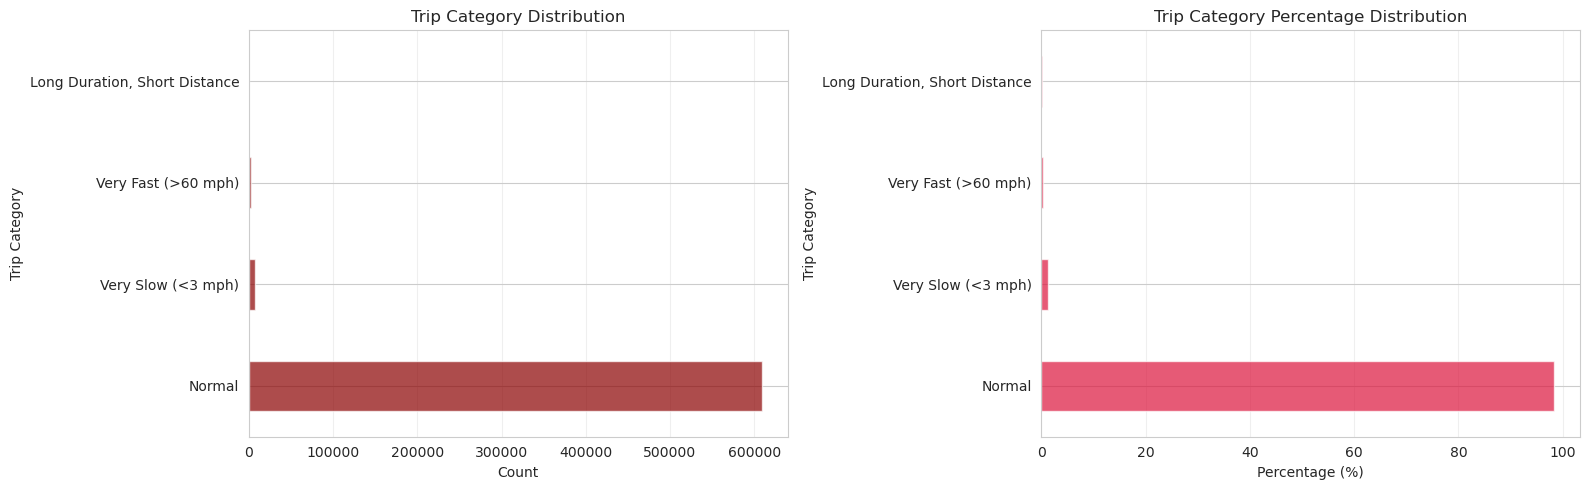

In [23]:
print("="*80)
print("IDENTIFYING PROBLEMATIC TRIPS")
print("="*80)

# Define "problematic" as: long duration (>60 min) but short distance (<5 miles)
df_original['speed_mph'] = df_original['trip_distance'] / (df_original['trip_duration'] / 60)
df_original['speed_mph'] = df_original['speed_mph'].replace([np.inf, -np.inf], np.nan)

# Identify different trip categories
df_original['trip_category'] = 'Normal'
df_original.loc[(df_original['trip_duration'] > 60) & (df_original['trip_distance'] < 5), 'trip_category'] = 'Long Duration, Short Distance'
df_original.loc[(df_original['trip_duration'] < 10) & (df_original['trip_distance'] > 20), 'trip_category'] = 'Short Duration, Long Distance'
df_original.loc[df_original['speed_mph'] < 3, 'trip_category'] = 'Very Slow (<3 mph)'
df_original.loc[df_original['speed_mph'] > 60, 'trip_category'] = 'Very Fast (>60 mph)'

print("\nTrip Category Distribution:")
category_counts = df_original['trip_category'].value_counts()
print(category_counts)
print(f"\nPercentage distribution:")
print((category_counts / len(df_original) * 100).round(2))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

category_counts.plot(kind='barh', ax=axes[0], color='darkred', alpha=0.7)
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Trip Category')
axes[0].set_title('Trip Category Distribution')
axes[0].grid(True, alpha=0.3, axis='x')

(category_counts / len(df_original) * 100).plot(kind='barh', ax=axes[1], color='crimson', alpha=0.7)
axes[1].set_xlabel('Percentage (%)')
axes[1].set_ylabel('Trip Category')
axes[1].set_title('Trip Category Percentage Distribution')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()


RATE_CODE IN PROBLEMATIC TRIPS

Problematic trips count: 230 (0.04%)

Rate Code distribution in problematic trips:


,Problematic (%),Normal (%),Difference
rate_code,,,
1.0,97.826087,96.897074,0.929013
5.0,2.173913,2.748343,-0.57443
2.0,0.0,0.222927,0.0
3.0,0.0,0.028235,0.0
4.0,0.0,0.102927,0.0
6.0,0.0,0.000492,0.0


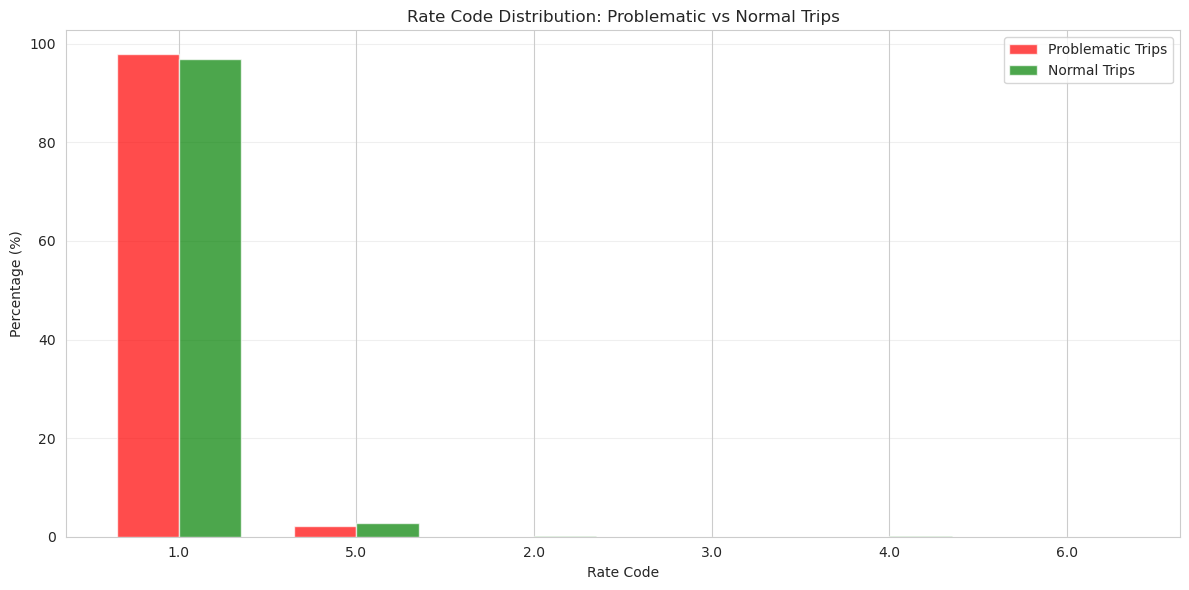


TRIP_TYPE IN PROBLEMATIC TRIPS

Trip Type distribution in problematic trips:


,Problematic (%),Normal (%),Difference
trip_type,,,
1.0,99.565217,97.566513,1.998704
2.0,0.434783,2.433487,-1.998704


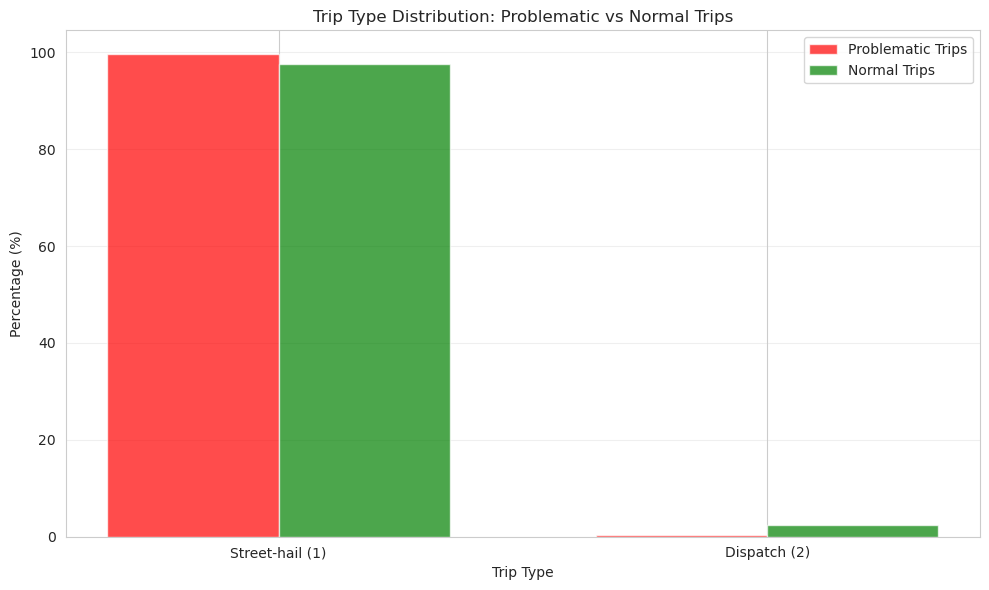

In [24]:
# Analyze rate_code and trip_type distribution in problematic categories
if 'rate_code' in df_original.columns:
    print("\n" + "="*80)
    print("RATE_CODE IN PROBLEMATIC TRIPS")
    print("="*80)
    
    problematic = df_original[df_original['trip_category'] == 'Long Duration, Short Distance']
    print(f"\nProblematic trips count: {len(problematic)} ({len(problematic)/len(df_original)*100:.2f}%)")
    
    print("\nRate Code distribution in problematic trips:")
    prob_rate_dist = problematic['rate_code'].value_counts(normalize=True) * 100
    normal_rate_dist = df_original[df_original['trip_category'] == 'Normal']['rate_code'].value_counts(normalize=True) * 100
    
    comparison = pd.DataFrame({
        'Problematic (%)': prob_rate_dist,
        'Normal (%)': normal_rate_dist,
        'Difference': prob_rate_dist - normal_rate_dist
    }).fillna(0).sort_values('Problematic (%)', ascending=False)
    
    display(comparison)
    
    # Visualize
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(comparison))
    width = 0.35
    
    ax.bar(x - width/2, comparison['Problematic (%)'], width, label='Problematic Trips', alpha=0.7, color='red')
    ax.bar(x + width/2, comparison['Normal (%)'], width, label='Normal Trips', alpha=0.7, color='green')
    
    ax.set_xlabel('Rate Code')
    ax.set_ylabel('Percentage (%)')
    ax.set_title('Rate Code Distribution: Problematic vs Normal Trips')
    ax.set_xticks(x)
    ax.set_xticklabels(comparison.index)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()

if 'trip_type' in df_original.columns:
    print("\n" + "="*80)
    print("TRIP_TYPE IN PROBLEMATIC TRIPS")
    print("="*80)
    
    problematic = df_original[df_original['trip_category'] == 'Long Duration, Short Distance']
    
    print("\nTrip Type distribution in problematic trips:")
    prob_type_dist = problematic['trip_type'].value_counts(normalize=True) * 100
    normal_type_dist = df_original[df_original['trip_category'] == 'Normal']['trip_type'].value_counts(normalize=True) * 100
    
    comparison = pd.DataFrame({
        'Problematic (%)': prob_type_dist,
        'Normal (%)': normal_type_dist,
        'Difference': prob_type_dist - normal_type_dist
    }).fillna(0).sort_values('Problematic (%)', ascending=False)
    
    display(comparison)
    
    # Visualize
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(comparison))
    width = 0.35
    
    ax.bar(x - width/2, comparison['Problematic (%)'], width, label='Problematic Trips', alpha=0.7, color='red')
    ax.bar(x + width/2, comparison['Normal (%)'], width, label='Normal Trips', alpha=0.7, color='green')
    
    ax.set_xlabel('Trip Type')
    ax.set_ylabel('Percentage (%)')
    ax.set_title('Trip Type Distribution: Problematic vs Normal Trips')
    ax.set_xticks(x)
    ax.set_xticklabels(['Street-hail (1)', 'Dispatch (2)'])
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()

## 7. Cross-Analysis: rate_code + trip_type

CROSS-ANALYSIS: RATE_CODE + TRIP_TYPE

Mean Trip Duration by Rate Code and Trip Type:


trip_type,1.0,2.0
rate_code,,
1.0,23.701354,38.980601
2.0,55.195016,11.850000
3.0,39.318740,NaN
4.0,62.553049,38.566667
5.0,37.153108,27.151115
6.0,2.155556,NaN


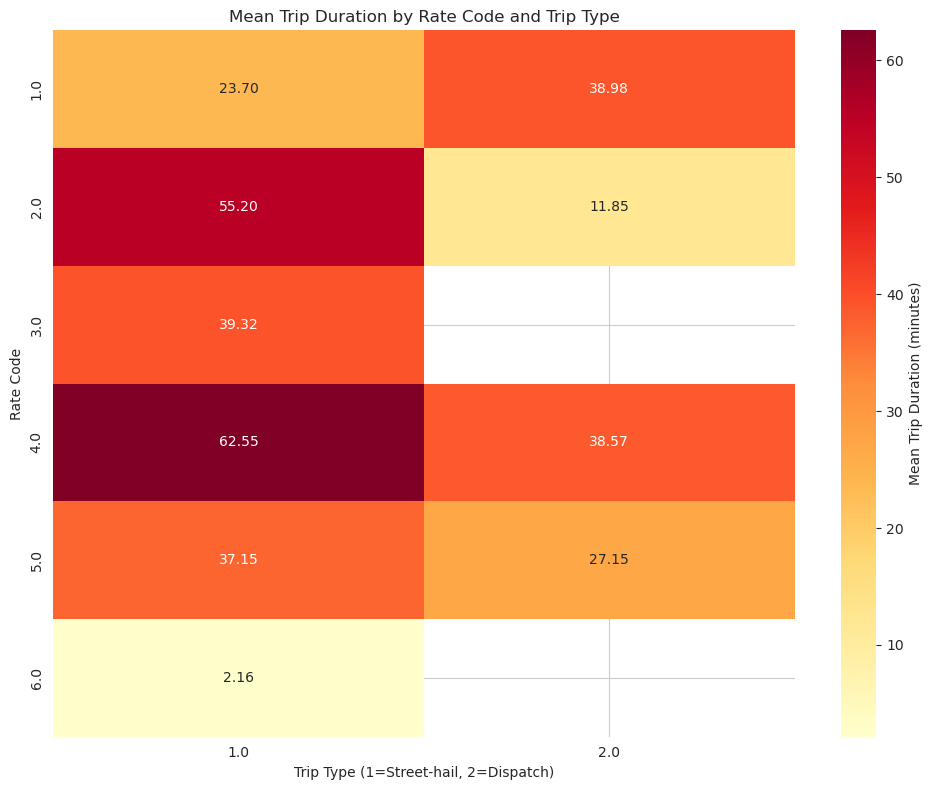


Trip Count by Rate Code and Trip Type:


trip_type,1.0,2.0
rate_code,,
1.0,598378,61
2.0,1428,1
3.0,201,0
4.0,634,4
5.0,2059,16332
6.0,3,0



Percentage Distribution:


trip_type,1.0,2.0
rate_code,,
1.0,96.65,0.01
2.0,0.23,0.00
3.0,0.03,0.00
4.0,0.10,0.00
5.0,0.33,2.64
6.0,0.00,0.00


In [25]:
if 'rate_code' in df_original.columns and 'trip_type' in df_original.columns:
    print("="*80)
    print("CROSS-ANALYSIS: RATE_CODE + TRIP_TYPE")
    print("="*80)
    
    # Create cross-tabulation
    cross_tab = pd.crosstab(df_original['rate_code'], df_original['trip_type'], 
                            values=df_original['trip_duration'], aggfunc='mean')
    
    print("\nMean Trip Duration by Rate Code and Trip Type:")
    display(cross_tab)
    
    # Visualize heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cross_tab, annot=True, fmt='.2f', cmap='YlOrRd', 
                cbar_kws={'label': 'Mean Trip Duration (minutes)'})
    plt.xlabel('Trip Type (1=Street-hail, 2=Dispatch)')
    plt.ylabel('Rate Code')
    plt.title('Mean Trip Duration by Rate Code and Trip Type')
    plt.tight_layout()
    plt.show()
    
    # Count distribution
    cross_count = pd.crosstab(df_original['rate_code'], df_original['trip_type'])
    print("\nTrip Count by Rate Code and Trip Type:")
    display(cross_count)
    
    # Percentage
    cross_pct = pd.crosstab(df_original['rate_code'], df_original['trip_type'], normalize='all') * 100
    print("\nPercentage Distribution:")
    display(cross_pct.round(2))

## 8. Recommendations and Conclusions

In [26]:
print("="*80)
print("SUMMARY AND RECOMMENDATIONS")
print("="*80)

print("\n🔍 KEY FINDINGS:")

# Finding 1: Problematic trips percentage
problematic_pct = (df_original['trip_category'] == 'Long Duration, Short Distance').sum() / len(df_original) * 100
print(f"\n1. Problematic trips (long duration, short distance): {problematic_pct:.2f}%")

# Finding 2: Rate code impact
if 'rate_code' in df_original.columns:
    rate_1_mean = df_original[df_original['rate_code'] == 1]['trip_duration'].mean()
    other_rates = df_original[df_original['rate_code'] != 1]
    if len(other_rates) > 0:
        other_mean = other_rates['trip_duration'].mean()
        print(f"2. Standard rate (1) mean duration: {rate_1_mean:.2f} min")
        print(f"   Other rates mean duration: {other_mean:.2f} min")
        print(f"   Difference: {other_mean - rate_1_mean:+.2f} min ({(other_mean/rate_1_mean - 1)*100:+.1f}%)")

# Finding 3: Trip type impact
if 'trip_type' in df_original.columns:
    type_1_mean = df_original[df_original['trip_type'] == 1]['trip_duration'].mean()
    type_2_mean = df_original[df_original['trip_type'] == 2]['trip_duration'].mean()
    print(f"3. Street-hail (1) mean duration: {type_1_mean:.2f} min")
    print(f"   Dispatch (2) mean duration: {type_2_mean:.2f} min")
    print(f"   Difference: {type_2_mean - type_1_mean:+.2f} min ({(type_2_mean/type_1_mean - 1)*100:+.1f}%)")

print("\n" + "="*80)
print("📋 RECOMMENDATIONS:")
print("="*80)

print("\n✅ Option 1: FILTER OUT PROBLEMATIC TRIPS")
print("   - Remove trips with non-standard rate codes (2, 3, 4, 5, 6)")
print("   - Only keep rate_code == 1 (standard metered fare)")
print(f"   - This would remove ~{(df_original['rate_code'] != 1).sum() / len(df_original) * 100:.1f}% of data")
print("   - But would make the remaining data much more predictable")

print("\n✅ Option 2: INCLUDE THESE FEATURES IN THE MODEL")
print("   - Add 'rate_code' as a categorical feature (dummy variables)")
print("   - Add 'trip_type' as a categorical feature (dummy variable)")
print("   - Model can learn different patterns for different trip types/rates")
print("   - Preserves all data but adds complexity")

print("\n✅ Option 3: SEPARATE MODELS")
print("   - Train one model for standard trips (rate_code=1, trip_type=1)")
print("   - Train separate models or use different logic for special trips")
print("   - Hybrid approach: most accurate but most complex")

print("\n✅ Option 4: ENGINEERED FEATURES")
print("   - Create 'is_standard_trip' binary feature (rate_code=1 AND trip_type=1)")
print("   - Create 'is_airport_trip' binary feature (rate_code=2 OR rate_code=3)")
print("   - Create 'is_negotiated' binary feature (rate_code=4 OR rate_code=5)")
print("   - Reduces dimensionality while preserving information")

print("\n" + "="*80)
print("🎯 RECOMMENDED NEXT STEPS:")
print("="*80)
print("1. Re-run data_cleaning.ipynb but KEEP rate_code and trip_type")
print("2. Option A: Filter to only rate_code==1 for simplest, most predictable model")
print("   Option B: Include rate_code and trip_type as features (dummy encoding)")
print("3. Re-train models and compare R² scores")
print("4. Check if the problematic predictions disappear")

# Save analysis results
results_summary = pd.DataFrame({
    'Category': ['Total Trips', 'Problematic Trips', 'Normal Trips'],
    'Count': [
        len(df_original),
        (df_original['trip_category'] == 'Long Duration, Short Distance').sum(),
        (df_original['trip_category'] == 'Normal').sum()
    ],
    'Percentage': [
        100.0,
        problematic_pct,
        (df_original['trip_category'] == 'Normal').sum() / len(df_original) * 100
    ]
})

print("\n📊 Summary saved:")
display(results_summary)
results_summary.to_csv('trip_type_rate_analysis_summary.csv', index=False)
print("\nResults saved to 'trip_type_rate_analysis_summary.csv'")

SUMMARY AND RECOMMENDATIONS

🔍 KEY FINDINGS:

1. Problematic trips (long duration, short distance): 0.04%
2. Standard rate (1) mean duration: 23.70 min
   Other rates mean duration: 31.29 min
   Difference: +7.59 min (+32.0%)
3. Street-hail (1) mean duration: 23.87 min
   Dispatch (2) mean duration: 27.20 min
   Difference: +3.33 min (+13.9%)

📋 RECOMMENDATIONS:

✅ Option 1: FILTER OUT PROBLEMATIC TRIPS
   - Remove trips with non-standard rate codes (2, 3, 4, 5, 6)
   - Only keep rate_code == 1 (standard metered fare)
   - This would remove ~3.3% of data
   - But would make the remaining data much more predictable

✅ Option 2: INCLUDE THESE FEATURES IN THE MODEL
   - Add 'rate_code' as a categorical feature (dummy variables)
   - Add 'trip_type' as a categorical feature (dummy variable)
   - Model can learn different patterns for different trip types/rates
   - Preserves all data but adds complexity

✅ Option 3: SEPARATE MODELS
   - Train one model for standard trips (rate_code=1, trip

,Category,Count,Percentage
0,Total Trips,619101,100.000000
1,Problematic Trips,230,0.037151
2,Normal Trips,609167,98.395415



Results saved to 'trip_type_rate_analysis_summary.csv'


## 9. Visualization: The Problem in Action

Let's recreate the XGBoost scatter plot pattern you described.

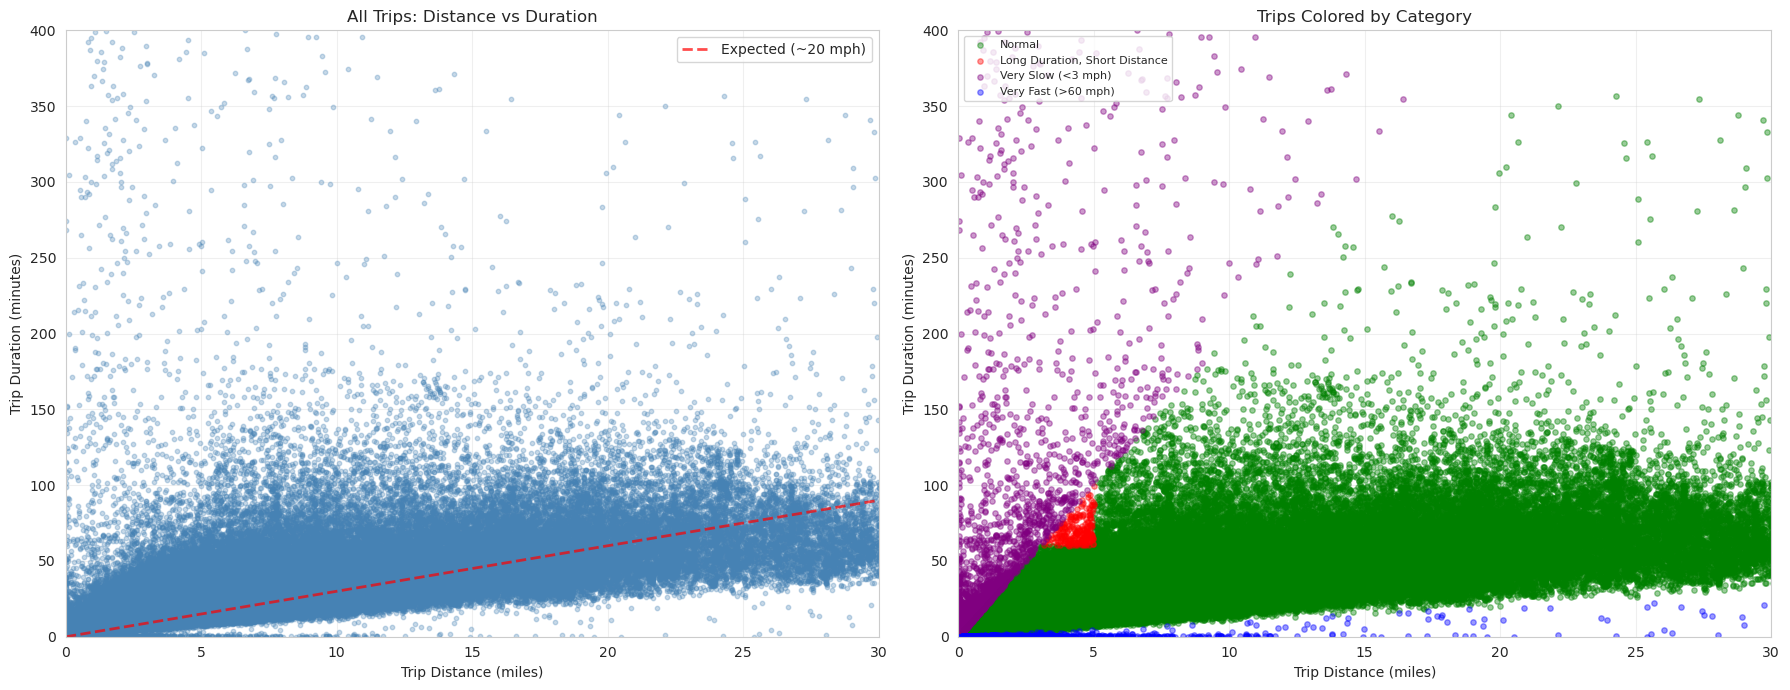

✅ Visualization saved to 'distance_duration_pattern.png'

This shows the pattern you described:
   - Green points (Normal): Follow expected distance-duration relationship
   - Red points (Problematic): Long duration despite short distance
   - These red points are likely what's breaking your model!


In [27]:
# Create visualization showing the pattern
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left plot: All trips
axes[0].scatter(df_original['trip_distance'], df_original['trip_duration'], 
               alpha=0.3, s=10, c='steelblue')
axes[0].set_xlabel('Trip Distance (miles)')
axes[0].set_ylabel('Trip Duration (minutes)')
axes[0].set_title('All Trips: Distance vs Duration')
axes[0].set_xlim(0, 30)
axes[0].set_ylim(0, 400)
axes[0].grid(True, alpha=0.3)

# Add reference line for expected relationship (assuming ~20 mph average)
x_ref = np.linspace(0, 30, 100)
y_ref = x_ref / 20 * 60  # distance / speed * 60 min/hr
axes[0].plot(x_ref, y_ref, 'r--', linewidth=2, label='Expected (~20 mph)', alpha=0.7)
axes[0].legend()

# Right plot: Color by trip category
colors = {'Normal': 'green', 'Long Duration, Short Distance': 'red', 
          'Short Duration, Long Distance': 'orange', 'Very Slow (<3 mph)': 'purple',
          'Very Fast (>60 mph)': 'blue'}

for category in df_original['trip_category'].unique():
    data = df_original[df_original['trip_category'] == category]
    axes[1].scatter(data['trip_distance'], data['trip_duration'], 
                   alpha=0.4, s=15, c=colors.get(category, 'gray'), 
                   label=category)

axes[1].set_xlabel('Trip Distance (miles)')
axes[1].set_ylabel('Trip Duration (minutes)')
axes[1].set_title('Trips Colored by Category')
axes[1].set_xlim(0, 30)
axes[1].set_ylim(0, 400)
axes[1].legend(loc='upper left', fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('distance_duration_pattern.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved to 'distance_duration_pattern.png'")
print("\nThis shows the pattern you described:")
print("   - Green points (Normal): Follow expected distance-duration relationship")
print("   - Red points (Problematic): Long duration despite short distance")
print("   - These red points are likely what's breaking your model!")